# Chapter-12: Checkpointers

# <font color="#800000">LangGraph Checkpointer</font>

## <font color="#3366FF">Motivation For Checkpointer</font>

### Example Of Graph Without Checkpointer

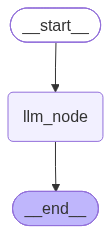

In [3]:
import os
from dotenv import load_dotenv
from langchain.messages import HumanMessage
from langchain_openai import ChatOpenAI
from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END, MessagesState

## Loading OpenAI API key from env file into an environment variable
load_dotenv()
os.environ["OPENAI_API_KEY"] = os.getenv('OPENAI_API_KEY')

## Define OpenAI Chat Model
llm = ChatOpenAI(model="gpt-5-mini") 

## Define llm node function
def llm_node(state: MessagesState):
    return {"messages": [llm.invoke(state["messages"])]}

## Create StateGraph
graph_builder = StateGraph(MessagesState)
graph_builder.add_node("llm_node", llm_node)
graph_builder.add_edge(START, "llm_node")
graph_builder.add_edge("llm_node", END)

## Compile graph
graph = graph_builder.compile()

## Visualize Graph
display(Image(graph.get_graph().draw_mermaid_png()))


#### Invoke Graph With Question

In [4]:
## Invoke Graph
response = graph.invoke({"messages": [HumanMessage(content="Which is the largest country in the world?")]})

## Print AI Message
response["messages"][-1].pretty_print()


================================== Ai Message ==================================

By land area: Russia is the largest country in the world — about 17.1 million square kilometers (≈6.6 million sq mi).

If you meant by population, the largest country is India (now the most populous nation, with roughly 1.4 billion people).


#### Invoke Graph With Follow-up Question

In [5]:
## Invoke Graph
response = graph.invoke({"messages": [HumanMessage(content="What is its capital?")]})

## Print AI Message
response["messages"][-1].pretty_print()


================================== Ai Message ==================================

I’m missing the referent — which country/region/organization do you mean by “its”? Please tell me the name (or paste the previous sentence) and I’ll give the capital.


### Example Of Graph With Checkpointer

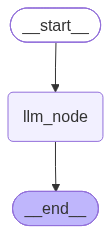

In [6]:
import os
from dotenv import load_dotenv
from langchain.messages import HumanMessage
from langchain_openai import ChatOpenAI
from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.checkpoint.memory import InMemorySaver

## Loading OpenAI API key from env file into an environment variable
load_dotenv()
os.environ["OPENAI_API_KEY"] = os.getenv('OPENAI_API_KEY')

## Define OpenAI Chat Model
llm = ChatOpenAI(model="gpt-5-mini") 

## Define llm node function
def llm_node(state: MessagesState):
    return {"messages": [llm.invoke(state["messages"])]}

## Create StateGraph
graph_builder = StateGraph(MessagesState)
graph_builder.add_node("llm_node", llm_node)
graph_builder.add_edge(START, "llm_node")
graph_builder.add_edge("llm_node", END)

## Initialize Checkpointer
checkpointer = InMemorySaver()

## Compile graph
graph = graph_builder.compile(checkpointer=checkpointer)

## Visualize Graph (optional)
display(Image(graph.get_graph().draw_mermaid_png()))


#### Invoke Graph With Question

In [7]:
## Define Thread Configuration
config = {"configurable": {"thread_id": "1"}}

## Invoke Graph
response = graph.invoke({"messages": [HumanMessage(content="Which is the largest country in the world?")]}, config=config)

## Print AI Message
response["messages"][-1].pretty_print()


================================== Ai Message ==================================

Russia. It covers about 17.1 million km² (≈6.6 million sq mi), making it the largest country by area.


In [8]:
## Define Thread Configuration
config = {"configurable": {"thread_id": "1"}}

## Invoke Graph
response = graph.invoke({"messages": [HumanMessage(content="What is its capital?")]}, config=config)

## Print AI Message
response["messages"][-1].pretty_print()


================================== Ai Message ==================================

Moscow. It is Russia’s capital and largest city, located on the Moskva River.


#### So What Is Happening Here?

In [9]:
## Print Messages
for msg in response['messages']:
    msg.pretty_print()


================================ Human Message =================================

Which is the largest country in the world?
================================== Ai Message ==================================

Russia. It covers about 17.1 million km² (≈6.6 million sq mi), making it the largest country by area.
================================ Human Message =================================

What is its capital?
================================== Ai Message ==================================

Moscow. It is Russia’s capital and largest city, located on the Moskva River.


## <font color="#3366FF">InMemorySaver Checkpointer</font>

### Example Of InMemorySaver

#### Setup

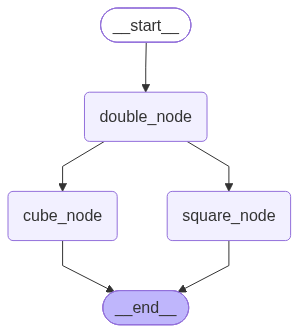

In [2]:
from typing_extensions import TypedDict
from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver

## Graph state schema
class State(TypedDict):
    input: int
    double: int
    square: int
    cube: int

## -----Define Nodes --------
def double_node(state: State):
    ## Doubles the input
    return {"double": state["input"]*2}

def square_node(state: State):
    ## Squares the Double
    return {"square": state["double"]*state["double"]}

def cube_node(state: State):
    ## Cubes the Double
    return {"cube": state["double"]*state["double"]*state["double"]}

## -----Create Graph --------
graph_builder = StateGraph(State)

graph_builder.add_node("double_node", double_node)
graph_builder.add_node("square_node", square_node)
graph_builder.add_node("cube_node", cube_node)

graph_builder.add_edge(START, "double_node")
graph_builder.add_edge("double_node", "square_node")
graph_builder.add_edge("double_node", "cube_node")
graph_builder.add_edge("square_node", END)
graph_builder.add_edge("cube_node", END)

## Initialize InMemorySaver Checkpointer
checkpointer = InMemorySaver()

## Compile Graph with InMemorySaver Checkpointer
graph = graph_builder.compile(checkpointer=checkpointer)

## Visualize Graph
display(Image(graph.get_graph().draw_mermaid_png()))


#### Invoke Graph

In [2]:
## Define Thread Configuration
config = {"configurable": {"thread_id": "m1"}}

## Invoke Graph and Print Output
print("Graph Output for thread_id m1:")
print(graph.invoke({"input": 2}, config=config))

## Define second Thread Configuration
config = {"configurable": {"thread_id": "m2"}}

## Invoke Graph and Print Output
print("\nGraph Output for thread_id m2:")
print(graph.invoke({"input": 7}, config=config))


Graph Output for thread_id m1:
{'input': 2, 'double': 4, 'square': 16, 'cube': 64}

Graph Output for thread_id m2:
{'input': 7, 'double': 14, 'square': 196, 'cube': 2744}


#### Get State Method

In [3]:
## Define Thread Configuration
config = {"configurable": {"thread_id": "m1"}}

## Get current StateSnapshot
print(graph.get_state(config))


StateSnapshot(values={'input': 2, 'double': 4, 'square': 16, 'cube': 64}, next=(), config={'configurable': {'thread_id': 'm1', 'checkpoint_ns': '', 'checkpoint_id': '1f1c8038-308c-66a8-8002-6392b552a0f8'}}, metadata={'source': 'loop', 'step': 2, 'parents': {}}, created_at='2026-10-14T19:14:43.404348+00:00', parent_config={'configurable': {'thread_id': 'm1', 'checkpoint_ns': '', 'checkpoint_id': '1f1c8038-3088-6d64-8001-14132756c8f1'}}, tasks=(), interrupts=())


In [4]:
## Define Thread Configuration
config = {"configurable": {"thread_id": "m2"}}

## Get current StateSnapshot
print(graph.get_state(config))


StateSnapshot(values={'input': 7, 'double': 14, 'square': 196, 'cube': 2744}, next=(), config={'configurable': {'thread_id': 'm2', 'checkpoint_ns': '', 'checkpoint_id': '1f1c8038-3095-6dfc-8002-cb85f022cdb8'}}, metadata={'source': 'loop', 'step': 2, 'parents': {}}, created_at='2026-10-14T19:14:43.408225+00:00', parent_config={'configurable': {'thread_id': 'm2', 'checkpoint_ns': '', 'checkpoint_id': '1f1c8038-3093-6444-8001-ce176aee3cff'}}, tasks=(), interrupts=())


#### Utility Function To Pretty Print StateSnapshot Details

In [5]:
def pretty_print_snapshot(snapshot):
    print(
        "StateSnapshot(\n"
        f"values={snapshot.values},\n"
        f"next={snapshot.next},\n"
        f"config={snapshot.config},\n"
        f"metadata={snapshot.metadata},\n"
        f"created_at='{snapshot.created_at}',\n"
        f"parent_config={snapshot.parent_config},\n"
        f"tasks={snapshot.tasks}\n",
        ")"
    )


#### Details Inside StateSnapshot

In [6]:
## Define Thread Configuration
config = {"configurable": {"thread_id": "m1"}}

## Pretty Print StateSnapshot
pretty_print_snapshot(graph.get_state(config))


StateSnapshot(
values={'input': 2, 'double': 4, 'square': 16, 'cube': 64},
next=(),
config={'configurable': {'thread_id': 'm1', 'checkpoint_ns': '', 'checkpoint_id': '1f1c8038-308c-66a8-8002-6392b552a0f8'}},
metadata={'source': 'loop', 'step': 2, 'parents': {}},
created_at='2026-10-14T19:14:43.404348+00:00',
parent_config={'configurable': {'thread_id': 'm1', 'checkpoint_ns': '', 'checkpoint_id': '1f1c8038-3088-6d64-8001-14132756c8f1'}},
tasks=()
 )


#### Get State History Method

In [7]:
## Define Thread Configuration
config = {"configurable": {"thread_id": "m1"}}

## Get History of StateSnapshot
list(graph.get_state_history(config))


[StateSnapshot(values={'input': 2, 'double': 4, 'square': 16, 'cube': 64}, next=(), config={'configurable': {'thread_id': 'm1', 'checkpoint_ns': '', 'checkpoint_id': '1f1c8038-308c-66a8-8002-6392b552a0f8'}}, metadata={'source': 'loop', 'step': 2, 'parents': {}}, created_at='2026-10-14T19:14:43.404348+00:00', parent_config={'configurable': {'thread_id': 'm1', 'checkpoint_ns': '', 'checkpoint_id': '1f1c8038-3088-6d64-8001-14132756c8f1'}}, tasks=(), interrupts=()),
 StateSnapshot(values={'input': 2, 'double': 4}, next=('square_node', 'cube_node'), config={'configurable': {'thread_id': 'm1', 'checkpoint_ns': '', 'checkpoint_id': '1f1c8038-3088-6d64-8001-14132756c8f1'}}, metadata={'source': 'loop', 'step': 1, 'parents': {}}, created_at='2026-10-14T19:14:43.402872+00:00', parent_config={'configurable': {'thread_id': 'm1', 'checkpoint_ns': '', 'checkpoint_id': '1f1c8038-3086-692e-8000-f351a24683fd'}}, tasks=(PregelTask(id='2fe7a3ac-c34a-d6ac-745d-c9a9c9db3a0b', name='square_node', path=('__pr

#### Update State Method

##### Put checkpoint_id value below according to what is shown in your session

In [10]:
config={'configurable': 
        {'thread_id': 'm1', 
         "checkpoint_ns": "", ## This is missing in book's snippet which is causing error now
         'checkpoint_id': '1f1c8038-3088-6d64-8001-14132756c8f1'}}

## Prett Print Snapshot
pretty_print_snapshot(graph.get_state(config))


StateSnapshot(
values={'input': 2, 'double': 4},
next=('square_node', 'cube_node'),
config={'configurable': {'thread_id': 'm1', 'checkpoint_ns': '', 'checkpoint_id': '1f1c8038-3088-6d64-8001-14132756c8f1'}},
metadata={'source': 'loop', 'step': 1, 'parents': {}},
created_at='2026-10-14T19:14:43.402872+00:00',
parent_config={'configurable': {'thread_id': 'm1', 'checkpoint_ns': '', 'checkpoint_id': '1f1c8038-3086-692e-8000-f351a24683fd'}},
tasks=(PregelTask(id='2fe7a3ac-c34a-d6ac-745d-c9a9c9db3a0b', name='square_node', path=('__pregel_pull', 'square_node'), error=None, interrupts=(), state=None, result={'square': 16}), PregelTask(id='d1fd54c8-236a-144c-f4c1-fd69ba847e36', name='cube_node', path=('__pregel_pull', 'cube_node'), error=None, interrupts=(), state=None, result={'cube': 64}))
 )


In [11]:
## Update State
graph.update_state(config, {'input': 2, 'double': 6}, as_node = 'double_node')


{'configurable': {'thread_id': 'm1',
  'checkpoint_ns': '',
  'checkpoint_id': '1f1c804d-27e7-6e0c-8002-b08e1b8a7bb8'}}

In [12]:
## Define Thread Configuration
config = {"configurable": {"thread_id": "m1"}}

## Get History of StateSnapshot
print(list(graph.get_state_history(config)))


[StateSnapshot(values={'input': 2, 'double': 6}, next=('square_node', 'cube_node'), config={'configurable': {'thread_id': 'm1', 'checkpoint_ns': '', 'checkpoint_id': '1f1c804d-27e7-6e0c-8002-b08e1b8a7bb8'}}, metadata={'source': 'update', 'step': 2, 'parents': {}}, created_at='2026-10-14T19:24:06.212483+00:00', parent_config={'configurable': {'thread_id': 'm1', 'checkpoint_ns': '', 'checkpoint_id': '1f1c8038-3088-6d64-8001-14132756c8f1'}}, tasks=(PregelTask(id='9915cbfc-f8db-45ad-1c7e-c1645c6b04a0', name='square_node', path=('__pregel_pull', 'square_node'), error=None, interrupts=(), state=None, result=None), PregelTask(id='18b4b10e-1108-f879-14c6-0d6d274bbc4a', name='cube_node', path=('__pregel_pull', 'cube_node'), error=None, interrupts=(), state=None, result=None)), interrupts=()), StateSnapshot(values={'input': 2, 'double': 4, 'square': 16, 'cube': 64}, next=(), config={'configurable': {'thread_id': 'm1', 'checkpoint_ns': '', 'checkpoint_id': '1f1c8038-308c-66a8-8002-6392b552a0f8'}}

### Restart Kernel

##### Execute Setup snippet above again before running below cell

In [3]:
## Define Thread Configuration
config = {"configurable": {"thread_id": "m1"}}

## Get History of StateSnapshot
print(list(graph.get_state_history(config)))


[]


## <font color="#3366FF">SqliteSaver Checkpointer</font>

### Example Of SqliteSaver

#### Setup

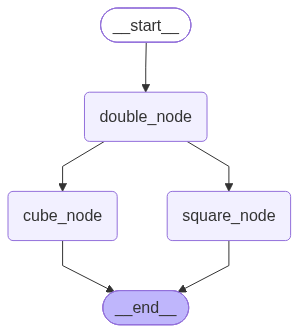

In [10]:
import os
from typing_extensions import TypedDict
from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.sqlite import SqliteSaver
import sqlite3

## Graph state
class State(TypedDict):
    input: int
    double: int
    square: int
    cube: int

## -----Define Nodes --------
def double_node(state: State):
    ## Doubles the input
    return {"double": state["input"]*2}

def square_node(state: State):
    ## Squares the Double
    return {"square": state["double"]*state["double"]}

def cube_node(state: State):
    ## Cubes the Double
    return {"cube": state["double"]*state["double"]*state["double"]}

## -----Create Graph --------
graph_builder = StateGraph(State)

graph_builder.add_node("double_node", double_node)
graph_builder.add_node("square_node", square_node)
graph_builder.add_node("cube_node", cube_node)

graph_builder.add_edge(START, "double_node")
graph_builder.add_edge("double_node", "square_node")
graph_builder.add_edge("double_node", "cube_node")
graph_builder.add_edge("square_node", END)
graph_builder.add_edge("cube_node", END)

## Create folder for SQLite DB 
os.makedirs("sqlitedb", exist_ok=True)

## Initialize SQLite Connection
conn = sqlite3.connect("sqlitedb/checkpoints.sqlite", check_same_thread=False)

## Initialize SqliteSaver
checkpointer = SqliteSaver(conn)

## Compile Graph with SqliteSaver Checkpointer
graph = graph_builder.compile(checkpointer=checkpointer)

## Visualize Graph (Optional)
display(Image(graph.get_graph().draw_mermaid_png()))


#### Invoke Graph

In [2]:
## Define Thread Configuration
config = {"configurable": {"thread_id": "s1"}}

## Invoke Graph
graph.invoke({"input": 6}, config=config)


{'input': 6, 'double': 12, 'square': 144, 'cube': 1728}

In [3]:
## Define Thread Configuration
config = {"configurable": {"thread_id": "s1"}}

## Get values from get_state()
print(graph.get_state(config))


StateSnapshot(values={'input': 6, 'double': 12, 'square': 144, 'cube': 1728}, next=(), config={'configurable': {'thread_id': 's1', 'checkpoint_ns': '', 'checkpoint_id': '1f1c8062-cecb-6c18-8002-c9d59fe2ceb5'}}, metadata={'source': 'loop', 'step': 2, 'parents': {}}, created_at='2026-10-14T19:33:47.426708+00:00', parent_config={'configurable': {'thread_id': 's1', 'checkpoint_ns': '', 'checkpoint_id': '1f1c8062-cec8-65b8-8001-b2a83f109178'}}, tasks=(), interrupts=())


#### Restart Kernel

##### Execute Setup snippet above again before running below cell

In [11]:
## Define Thread Configuration
config = {"configurable": {"thread_id": "s1"}}

## Get values from get_state()
print(graph.get_state(config))


StateSnapshot(values={'input': 6, 'double': 12, 'square': 144, 'cube': 1728}, next=(), config={'configurable': {'thread_id': 's1', 'checkpoint_ns': '', 'checkpoint_id': '1f1c8062-cecb-6c18-8002-c9d59fe2ceb5'}}, metadata={'source': 'loop', 'step': 2, 'parents': {}}, created_at='2026-10-14T19:33:47.426708+00:00', parent_config={'configurable': {'thread_id': 's1', 'checkpoint_ns': '', 'checkpoint_id': '1f1c8062-cec8-65b8-8001-b2a83f109178'}}, tasks=(), interrupts=())


## <font color="#3366FF">PostgresSaver Checkpointer</font>

### Set Up In Postgres DB

##### Important: Change DB_URI according to your Postgres setup first

In [8]:
import psycopg
from langgraph.checkpoint.postgres import PostgresSaver

## Define Postgres connection string
DB_URI = "postgresql://ankur@localhost/postgres?options=-c%20search_path%3Dlanggraph"

## Create "langgraph" schema in database
with psycopg.connect(DB_URI, autocommit=True) as conn:
    with conn.cursor() as cur:
        cur.execute("CREATE SCHEMA IF NOT EXISTS langgraph")

## Create Tables for PostgresSaver
with PostgresSaver.from_conn_string(DB_URI) as checkpointer:
    checkpointer.setup()


### Example Of PostgresSaver

In [2]:
import os
from typing_extensions import TypedDict
from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.postgres import PostgresSaver

## Graph state
class State(TypedDict):
    input: int
    double: int
    square: int
    cube: int

## -----Define Nodes --------
def double_node(state: State):
    ## Doubles the input
    return {"double": state["input"]*2}

def square_node(state: State):
    ## Squares the Double
    return {"square": state["double"]*state["double"]}

def cube_node(state: State):
    ## Cubes the Double
    return {"cube": state["double"]*state["double"]*state["double"]}

## -----Create Graph --------
graph_builder = StateGraph(State)

graph_builder.add_node("double_node", double_node)
graph_builder.add_node("square_node", square_node)
graph_builder.add_node("cube_node", cube_node)

graph_builder.add_edge(START, "double_node")
graph_builder.add_edge("double_node", "square_node")
graph_builder.add_edge("double_node", "cube_node")
graph_builder.add_edge("square_node", END)
graph_builder.add_edge("cube_node", END)


#### Compile & Graph

In [10]:
## Define Postgres connection string
DB_URI = "postgresql://ankur@localhost/postgres?options=-c%20search_path%3Dlanggraph"

## Initialize PostgresSaver checkpointer
with PostgresSaver.from_conn_string(DB_URI) as checkpointer:

    ## Compile graph with PostgresSaver checkpointer
    graph = graph_builder.compile(checkpointer=checkpointer)

    ## Visualize Graph (Optional)
    #display(Image(graph.get_graph().draw_mermaid_png()))

    ## Define Thread Configuration
    config = {"configurable": {"thread_id": "p1"}}
    
    ## Invoke Graph
    print(graph.invoke({"input": 9}, config=config))


{'input': 9, 'double': 18, 'square': 324, 'cube': 5832}


#### Restart Kernel & Get State

##### Execute Setup snippet above again before running below cell

In [3]:
## Define Postgres connection string
DB_URI = "postgresql://ankur@localhost/postgres?options=-c%20search_path%3Dlanggraph"

## Initialize PostgresSaver checkpointer
with PostgresSaver.from_conn_string(DB_URI) as checkpointer:
    
    ## Compile graph with PostgresSaver checkpointer
    graph = graph_builder.compile(checkpointer=checkpointer)
    
    ## Define Thread Configuration
    config = {"configurable": {"thread_id": "p1"}}

    ## Get values from get_state()
    print(graph.get_state(config))


StateSnapshot(values={'input': 9, 'double': 18, 'square': 324, 'cube': 5832}, next=(), config={'configurable': {'thread_id': 'p1', 'checkpoint_ns': '', 'checkpoint_id': '1f1c8070-e84b-63ec-801e-b3aca005a12d'}}, metadata={'step': 30, 'source': 'loop', 'parents': {}}, created_at='2026-10-14T19:40:05.909287+00:00', parent_config={'configurable': {'thread_id': 'p1', 'checkpoint_ns': '', 'checkpoint_id': '1f1c8070-e839-6bec-801d-6c33e22a9651'}}, tasks=(), interrupts=())
